In [1]:
# Install required libraries
!pip install -q transformers datasets librosa evaluate jiwer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 42.6 MB/s eta 0:00:0000:0100:01


In [2]:
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


# gpt given

In [3]:
# import os
# # Force the environment to only see the first T4 GPU
# os.environ["CUDA_VISIBLE_DEVICES"] = "0"

# import torch
# print(f"GPUs available: {torch.cuda.device_count()}") 
# # This should now print: GPUs available: 1

In [4]:
!pip install -q -U transformers datasets accelerate evaluate jiwer peft soundfile librosa

import os
import re
import gc
import math
import random
import unicodedata
from dataclasses import dataclass
from typing import Any, Dict, List, Union

import numpy as np
import pandas as pd
import soundfile as sf
import matplotlib.pyplot as plt
import torch
import transformers
import peft
import accelerate

from sklearn.model_selection import train_test_split

from datasets import Dataset, Audio
import evaluate
from jiwer import wer as jiwer_wer, cer as jiwer_cer

from peft import LoraConfig, PeftModel, PeftType

from transformers import (
    WhisperProcessor,
    WhisperForConditionalGeneration,
    Seq2SeqTrainer,
    Seq2SeqTrainingArguments,
    EarlyStoppingCallback,
    set_seed,
)

SEED = 42
set_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)

print("transformers", transformers.__version__)
print("peft", peft.__version__)
print("accelerate", accelerate.__version__)

DATA_DIR = "/kaggle/input/competitions/multilingual-speech-recognition/"   # change if needed

train_df = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
test_df = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))
sample_sub = pd.read_csv(os.path.join(DATA_DIR, "sample_submission.csv"))

audio_col = "audio"
text_col = "text"

AUDIO_ROOTS = [
    os.path.join(DATA_DIR, "competition_data"),
    os.path.join(DATA_DIR, "competition_data", "train"),
    os.path.join(DATA_DIR, "competition_data", "test"),
    os.path.join(DATA_DIR, "train"),
    os.path.join(DATA_DIR, "test"),
]

def resolve_audio_path(fname: str) -> str:
    for root in AUDIO_ROOTS:
        path = os.path.join(root, fname)
        if os.path.exists(path):
            return path
    raise FileNotFoundError(f"Could not find {fname} under any of: {AUDIO_ROOTS}")

train_df["row_id"] = np.arange(len(train_df))
train_df["audio_path"] = train_df[audio_col].map(resolve_audio_path)
test_df["audio_path"] = test_df[audio_col].map(resolve_audio_path)

def clean_text(x: str) -> str:
    return re.sub(r"\s+", " ", str(x).strip())

train_df[text_col] = train_df[text_col].map(clean_text)

print("Resolved first 3 train paths:")
display(train_df[[audio_col, "audio_path"]].head(3))


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 67.0 MB/s eta 0:00:0000:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 527.0/527.0 kB 35.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 383.7/383.7 kB 18.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 637.4/637.4 kB 44.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 106.2 MB/s eta 0:00:0000:01
transformers 5.5.0
peft 0.18.1
accelerate 1.13.0
Resolved first 3 train paths:


,audio,audio_path
0,audio_00000.wav,/kaggle/input/competitions/multilingual-speech...
1,audio_00001.wav,/kaggle/input/competitions/multilingual-speech...
2,audio_00002.wav,/kaggle/input/competitions/multilingual-speech...


Total samples: 2000
Total hours: 4.276
Average duration: 7.697
Max duration: 24.19
Short clips (<3 words): 17
Duplicate transcript rate: 0.0015

Script distribution:
script
LATIN         998
DEVANAGARI    508
TAMIL         494
Name: count, dtype: int64

Duration / text stats:
          duration      n_words      n_chars  chars_per_sec  words_per_sec  \
count  2000.000000  2000.000000  2000.000000    2000.000000    2000.000000   
mean      7.696910    17.941000   106.281500      12.510489       2.157223   
std       4.684160    14.105247    84.859335       4.189082       0.610331   
min       1.022000     1.000000     4.000000       2.547554       0.480764   
25%       4.040000     7.000000    39.000000       9.320593       1.719902   
50%       5.728521    12.000000    59.000000      11.755147       2.090822   
75%      11.875500    28.000000   185.000000      15.454005       2.589230   
max      24.190000    62.000000   444.000000      29.103491       4.934211   

       punct_ratio  

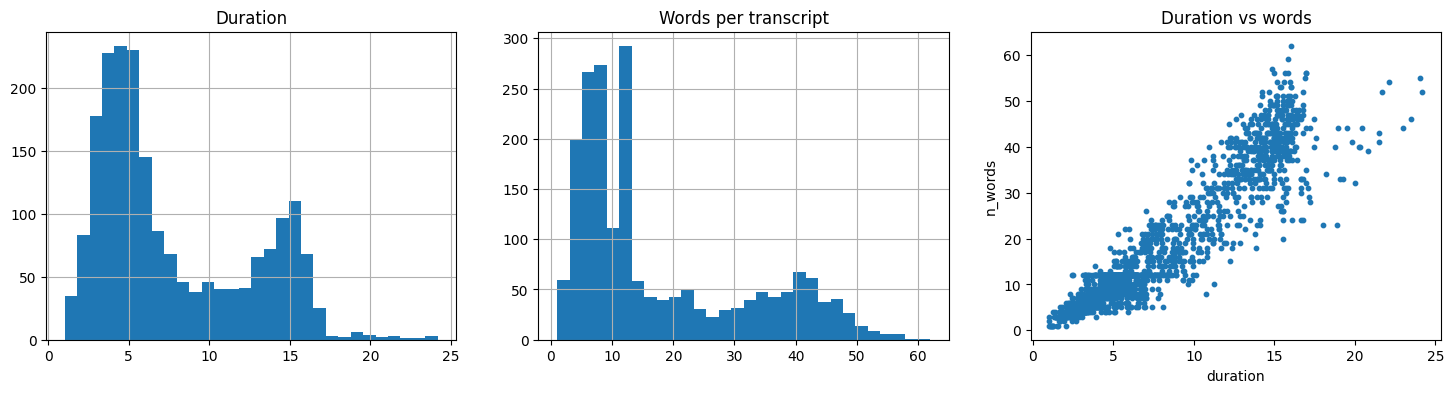


Top duplicate transcripts:


text
इसमें से वो पचास भारतीय और बीस विदेशी खिलाड़ी चुन सकेंगे                                                                                                                                                                                             2
मैं अपनी दस साल की बेटी के साथ खड़ी उन तस्वीरों और                                                                                                                                                                                                   2
अगले हफ़्ते सैंड्रा और मोशे एक बार फिर उसी घर में होंगे                                                                                                                                                                                              2
புது செய்யுள் அந்த மாதிரி அளவுகோல்கள் எதுவும் இல்லாமல் வரையறைகள் எதுவும் இல்லாமல் தமிழ் வார்த்தைகளால் கவிஞர்களுக்கு என்ன தோன்றதோ அதை எழுதுகிறத வந்து                                                                                                 1
THEY WE


Likely odd cases:


,audio,text,duration,n_words,script
982,audio_00982.wav,கோவில்லர்ந்து,2.080021,1,TAMIL
1781,audio_01781.wav,சாய்நிவி,1.570000,1,TAMIL
1787,audio_01787.wav,பின்பற்றவும்,1.488021,1,TAMIL
1820,audio_01820.wav,விளையாடு,1.253021,1,TAMIL
1363,audio_01363.wav,முன்னோக்கி,1.247021,1,TAMIL
1875,audio_01875.wav,பறவை,1.189021,1,TAMIL
1838,audio_01838.wav,விசித்திரமானதுங்க,1.121000,1,TAMIL
664,audio_00664.wav,அப்பறம்,1.120021,1,TAMIL
1931,audio_01931.wav,மரம்,1.068021,1,TAMIL
178,audio_00178.wav,பிரம்மாண்டமானதுங்க,1.024000,1,TAMIL


In [5]:
def get_duration(path: str) -> float:
    info = sf.info(path)
    return info.frames / info.samplerate

def detect_script(text: str) -> str:
    counts = {}
    for ch in str(text):
        if not ch.isalpha():
            continue
        name = unicodedata.name(ch, "")
        for script in [
            "LATIN", "TAMIL", "DEVANAGARI", "BENGALI", "TELUGU",
            "KANNADA", "MALAYALAM", "GUJARATI", "GURMUKHI",
            "ORIYA", "ARABIC", "CYRILLIC"
        ]:
            if script in name:
                counts[script] = counts.get(script, 0) + 1
                break
        else:
            counts["OTHER"] = counts.get("OTHER", 0) + 1
    return max(counts, key=counts.get) if counts else "OTHER"

train_df["duration"] = train_df["audio_path"].map(get_duration)
train_df["n_words"] = train_df[text_col].map(lambda x: len(str(x).split()))
train_df["n_chars"] = train_df[text_col].map(lambda x: len(str(x)))
train_df["chars_per_sec"] = train_df["n_chars"] / train_df["duration"].clip(lower=1e-6)
train_df["words_per_sec"] = train_df["n_words"] / train_df["duration"].clip(lower=1e-6)
train_df["script"] = train_df[text_col].map(detect_script)
train_df["is_upper_heavy"] = train_df[text_col].map(
    lambda x: sum(ch.isupper() for ch in str(x)) / max(1, sum(ch.isalpha() for ch in str(x))) > 0.6
)
train_df["has_digit"] = train_df[text_col].str.contains(r"\d", regex=True)
train_df["punct_ratio"] = train_df[text_col].map(
    lambda x: sum(not ch.isalnum() and not ch.isspace() for ch in str(x)) / max(1, len(str(x)))
)

print("Total samples:", len(train_df))
print("Total hours:", round(train_df["duration"].sum() / 3600, 3))
print("Average duration:", round(train_df["duration"].mean(), 3))
print("Max duration:", round(train_df["duration"].max(), 3))
print("Short clips (<3 words):", int((train_df["n_words"] < 3).sum()))
print("Duplicate transcript rate:", round(1 - train_df[text_col].nunique() / len(train_df), 4))
print("\nScript distribution:")
print(train_df["script"].value_counts())
print("\nDuration / text stats:")
print(train_df[["duration", "n_words", "n_chars", "chars_per_sec", "words_per_sec", "punct_ratio"]].describe())

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
train_df["duration"].hist(bins=30, ax=axes[0])
axes[0].set_title("Duration")
train_df["n_words"].hist(bins=30, ax=axes[1])
axes[1].set_title("Words per transcript")
axes[2].scatter(train_df["duration"], train_df["n_words"], s=10)
axes[2].set_title("Duration vs words")
axes[2].set_xlabel("duration")
axes[2].set_ylabel("n_words")
plt.show()

print("\nTop duplicate transcripts:")
display(train_df[text_col].value_counts().head(10))

print("\nLikely odd cases:")
display(
    train_df.sort_values(["n_words", "duration"], ascending=[True, False])[
        [audio_col, text_col, "duration", "n_words", "script"]
    ].head(15)
)

In [6]:
# Collapse very rare scripts into RARE for safer stratification
script_counts = train_df["script"].value_counts()
train_df["script_bucket"] = train_df["script"].where(train_df["script"].map(script_counts) >= 5, "RARE")

# Mix duration into the split so validation isn't biased toward only short or long clips
train_df["dur_bin"] = pd.qcut(train_df["duration"], q=4, duplicates="drop").astype(str)
train_df["stratify_key"] = train_df["script_bucket"] + "__" + train_df["dur_bin"]

# If any combined bucket is too rare, back off to script only
combo_counts = train_df["stratify_key"].value_counts()
train_df.loc[train_df["stratify_key"].map(combo_counts) < 2, "stratify_key"] = train_df["script_bucket"]

try:
    tr_df, va_df = train_test_split(
        train_df,
        test_size=0.12,
        random_state=SEED,
        stratify=train_df["stratify_key"],
    )
except ValueError:
    tr_df, va_df = train_test_split(
        train_df,
        test_size=0.12,
        random_state=SEED,
        stratify=train_df["script_bucket"],
    )

tr_df = tr_df.reset_index(drop=True)
va_df = va_df.reset_index(drop=True)

print("Train size:", len(tr_df))
print("Val size:", len(va_df))
print("\nTrain script mix:")
print(tr_df["script_bucket"].value_counts(normalize=True).round(3))
print("\nVal script mix:")
print(va_df["script_bucket"].value_counts(normalize=True).round(3))

# # Pick one sample from your processed dataset
# sample = train_proc[0]

# print(f"Feature Shape: {torch.tensor(sample['input_features']).shape}") 
# # Should be [80, 3000] (80 mel bins, 3000 time frames for 30s)

# print(f"Input Length: {sample['input_length']:.2f} seconds")

Train size: 1760
Val size: 240

Train script mix:
script_bucket
LATIN         0.499
DEVANAGARI    0.254
TAMIL         0.247
Name: proportion, dtype: float64

Val script mix:
script_bucket
LATIN         0.496
DEVANAGARI    0.254
TAMIL         0.250
Name: proportion, dtype: float64


# Run gpt

In [7]:
def to_hf_dataset(df: pd.DataFrame, include_text: bool = True) -> Dataset:
    data = {
        "audio": df["audio_path"].tolist(),
    }
    if include_text:
        data["text"] = df[text_col].tolist()
    return Dataset.from_dict(data).cast_column("audio", Audio(sampling_rate=16000))

train_ds = to_hf_dataset(tr_df, include_text=True)
val_ds = to_hf_dataset(va_df, include_text=True)
test_ds = to_hf_dataset(test_df.assign(text=""), include_text=False)

In [8]:
MODEL_NAME = "openai/whisper-small"

processor = WhisperProcessor.from_pretrained(MODEL_NAME, task="transcribe")
processor.tokenizer.set_prefix_tokens(task="transcribe")

def prepare_train_batch(batch):
    audio = batch["audio"]
    batch["input_features"] = processor.feature_extractor(
        audio["array"],
        sampling_rate=audio["sampling_rate"]
    ).input_features[0]
    batch["labels"] = processor.tokenizer(batch["text"]).input_ids
    batch["input_length"] = len(audio["array"]) / audio["sampling_rate"]
    return batch

def prepare_test_batch(batch):
    audio = batch["audio"]
    batch["input_features"] = processor.feature_extractor(
        audio["array"],
        sampling_rate=audio["sampling_rate"]
    ).input_features[0]
    batch["input_length"] = len(audio["array"]) / audio["sampling_rate"]
    return batch

train_proc = train_ds.map(prepare_train_batch, remove_columns=train_ds.column_names)
val_proc = val_ds.map(prepare_train_batch, remove_columns=val_ds.column_names)
test_proc = test_ds.map(prepare_test_batch, remove_columns=test_ds.column_names)

sample = train_proc[0]
print(f"Feature Shape: {torch.tensor(sample['input_features']).shape}")
print(f"Input Length: {sample['input_length']:.2f} seconds")


preprocessor_config.json: 0.00B [00:00, ?B/s]

config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

...

special_tokens_map.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/1760 [00:00<?, ? examples/s]

Map:   0%|          | 0/240 [00:00<?, ? examples/s]

Map:   0%|          | 0/100 [00:00<?, ? examples/s]

Feature Shape: torch.Size([80, 3000])
Input Length: 4.64 seconds


In [9]:
@dataclass
class DataCollatorSpeechSeq2SeqWithPadding:
    processor: Any
    decoder_start_token_id: int

    def __call__(self, features: List[Dict[str, Union[List[int], np.ndarray]]]) -> Dict[str, torch.Tensor]:
        input_features = [{"input_features": f["input_features"]} for f in features]
        batch = self.processor.feature_extractor.pad(input_features, return_tensors="pt")

        if "labels" in features[0]:
            label_features = [{"input_ids": f["labels"]} for f in features]
            labels_batch = self.processor.tokenizer.pad(label_features, return_tensors="pt")

            labels = labels_batch["input_ids"].masked_fill(labels_batch.attention_mask.ne(1), -100)

            if (labels[:, 0] == self.decoder_start_token_id).all().cpu().item():
                labels = labels[:, 1:]

            batch["labels"] = labels

        return batch

data_collator = DataCollatorSpeechSeq2SeqWithPadding(
    processor=processor,
    decoder_start_token_id=processor.tokenizer.convert_tokens_to_ids("<|startoftranscript|>")
)

In [10]:
wer_metric = evaluate.load("wer")
cer_metric = evaluate.load("cer")

def normalize_for_metric(x: str) -> str:
    return re.sub(r"\s+", " ", str(x).strip())

def compute_metrics(pred):
    pred_ids = pred.predictions
    if isinstance(pred_ids, tuple):
        pred_ids = pred_ids[0]

    label_ids = pred.label_ids.copy()
    label_ids[label_ids == -100] = processor.tokenizer.pad_token_id

    pred_str = processor.tokenizer.batch_decode(pred_ids, skip_special_tokens=True)
    label_str = processor.tokenizer.batch_decode(label_ids, skip_special_tokens=True)

    pred_str = [normalize_for_metric(x) for x in pred_str]
    label_str = [normalize_for_metric(x) for x in label_str]

    ref_words = np.array([max(1, len(x.split())) for x in label_str], dtype=np.float32)
    pred_words = np.array([len(x.split()) for x in pred_str], dtype=np.float32)

    metrics = {
        "wer": wer_metric.compute(predictions=pred_str, references=label_str),
        "cer": cer_metric.compute(predictions=pred_str, references=label_str),
        "exact_match": float(np.mean([p == r for p, r in zip(pred_str, label_str)])),
        "empty_pred_rate": float(np.mean([p == "" for p in pred_str])),
        "pred_ref_word_ratio": float(np.mean(pred_words / ref_words)),
        # diagnostic only, not for model selection
        "wer_lower_diag": wer_metric.compute(
            predictions=[x.lower() for x in pred_str],
            references=[x.lower() for x in label_str]
        ),
    }
    return metrics

class BatchLossSeq2SeqTrainer(Seq2SeqTrainer):
    def evaluate(self, *args, **kwargs):
        self._eval_batch_losses = []
        metrics = super().evaluate(*args, **kwargs)

        if len(self._eval_batch_losses) > 0:
            arr = np.array(self._eval_batch_losses, dtype=np.float32)
            extra = {
                "eval_batch_loss_mean": float(arr.mean()),
                "eval_batch_loss_std": float(arr.std()),
                "eval_batch_loss_median": float(np.median(arr)),
                "eval_batch_loss_p90": float(np.percentile(arr, 90)),
            }
            metrics.update(extra)
            self.log(extra)

        return metrics

    def prediction_step(self, model, inputs, prediction_loss_only, ignore_keys=None):
        loss, generated_tokens, labels = super().prediction_step(
            model, inputs, prediction_loss_only, ignore_keys=ignore_keys
        )

        if hasattr(self, "_eval_batch_losses") and (loss is not None) and (not model.training):
            self._eval_batch_losses.append(loss.detach().float().cpu().item())

        return loss, generated_tokens, labels

In [11]:
class WhisperTuner(PeftModel):
    """
    Whisper-compatible PEFT wrapper.

    Why this exists:
    - Generic PEFT seq2seq wrappers assume text encoder inputs called `input_ids`.
    - Whisper encoder takes `input_features`.
    - With recent peft/transformers combinations, the generic wrapper can forward
      `input_ids` into Whisper internals and crash with:
      `got multiple values for keyword argument 'input_ids'`.
    """

    def __init__(self, model: torch.nn.Module, peft_config, adapter_name: str = "default") -> None:
        super().__init__(model, peft_config, adapter_name)
        self.base_model_prepare_inputs_for_generation = self.base_model.prepare_inputs_for_generation
        self.base_model_prepare_encoder_decoder_kwargs_for_generation = (
            self.base_model._prepare_encoder_decoder_kwargs_for_generation
        )

    def forward(
        self,
        input_features=None,
        attention_mask=None,
        decoder_input_ids=None,
        decoder_attention_mask=None,
        decoder_inputs_embeds=None,
        labels=None,
        output_attentions=None,
        output_hidden_states=None,
        return_dict=None,
        task_ids=None,
        **kwargs,
    ):
        peft_config = self.active_peft_config

        if peft_config.is_prompt_learning:
            raise NotImplementedError("Prompt-learning PEFT methods are not used in this notebook.")

        if peft_config.peft_type == PeftType.POLY:
            kwargs["task_ids"] = task_ids

        with self._enable_peft_forward_hooks(**kwargs):
            kwargs = {k: v for k, v in kwargs.items() if k not in self.special_peft_forward_args}
            return self.base_model(
                input_features=input_features,
                attention_mask=attention_mask,
                decoder_input_ids=decoder_input_ids,
                decoder_attention_mask=decoder_attention_mask,
                decoder_inputs_embeds=decoder_inputs_embeds,
                labels=labels,
                output_attentions=output_attentions,
                output_hidden_states=output_hidden_states,
                return_dict=return_dict,
                **kwargs,
            )

    def generate(self, **kwargs):
        peft_config = self.active_peft_config

        if peft_config.is_prompt_learning:
            raise NotImplementedError("Prompt-learning PEFT methods are not used in this notebook.")

        self.base_model.prepare_inputs_for_generation = self.prepare_inputs_for_generation
        self.base_model._prepare_encoder_decoder_kwargs_for_generation = (
            self._prepare_encoder_decoder_kwargs_for_generation
        )

        try:
            with self._enable_peft_forward_hooks(**kwargs):
                kwargs = {k: v for k, v in kwargs.items() if k not in self.special_peft_forward_args}
                outputs = self.base_model.generate(**kwargs)
        finally:
            self.base_model.prepare_inputs_for_generation = self.base_model_prepare_inputs_for_generation
            self.base_model._prepare_encoder_decoder_kwargs_for_generation = (
                self.base_model_prepare_encoder_decoder_kwargs_for_generation
            )

        return outputs

    def prepare_inputs_for_generation(self, *args, task_ids: torch.Tensor = None, **kwargs):
        model_kwargs = self.base_model_prepare_inputs_for_generation(*args, **kwargs)
        if self.active_peft_config.peft_type == PeftType.POLY:
            model_kwargs["task_ids"] = task_ids
        return model_kwargs


model = WhisperForConditionalGeneration.from_pretrained(MODEL_NAME)

model.config.use_cache = False
model.config.forced_decoder_ids = None
model.generation_config.forced_decoder_ids = None
model.generation_config.task = "transcribe"
model.generation_config.language = None

model.gradient_checkpointing_enable()

# Whisper uses convolutional audio inputs, not token embeddings.
# This hook is the PEFT Whisper example pattern for gradient checkpointing.
def make_inputs_require_grad(module, input, output):
    output.requires_grad_(True)

model.model.encoder.conv1.register_forward_hook(make_inputs_require_grad)

lora_config = LoraConfig(
    inference_mode=False,
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    target_modules=["q_proj", "v_proj"],
)

model = WhisperTuner(model, lora_config)
model.print_trainable_parameters()


model.safetensors:   0%|          | 0.00/967M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

generation_config.json: 0.00B [00:00, ?B/s]

trainable params: 1,769,472 || all params: 243,504,384 || trainable%: 0.7267


In [12]:
# # Calculate steps based on your 1,760 training samples
# per_device_train_batch_size = 8
# gradient_accumulation_steps = 2
# effective_batch = per_device_train_batch_size * gradient_accumulation_steps
# steps_per_epoch = len(train_proc) // effective_batch

# training_args = Seq2SeqTrainingArguments(
#     output_dir="/kaggle/working/whisper_small_lora",
#     per_device_train_batch_size=per_device_train_batch_size,
#     gradient_accumulation_steps=gradient_accumulation_steps,
#     per_device_eval_batch_size=8,
    
#     # Optimizer settings for 0.1 WER
#     learning_rate=1e-4,           # Stable rate to avoid NaN
#     warmup_ratio=0.1,             # 10% warmup for multi-script stability
#     num_train_epochs=5,           # Enough for 4.3 hours of data
#     weight_decay=0.01,
#     max_grad_norm=1.0,            # Prevents exploding gradients
    
#     # Evaluation & Checkpointing
#     fp16=True,                    # Works perfectly on T4
#     eval_strategy="steps",        
#     eval_steps=steps_per_epoch // 2, # Validate twice per epoch
#     save_strategy="steps",
#     save_steps=steps_per_epoch // 2,
#     logging_steps=25,
#     load_best_model_at_end=True,
#     metric_for_best_model="wer",
#     greater_is_better=False,
    
#     # Generation settings for Beam Search
#     predict_with_generate=True,
#     generation_max_length=225,
#     generation_num_beams=5,       # CRITICAL: Increases accuracy significantly
    
#     # Infrastructure
#     report_to="none",
#     remove_unused_columns=True,   # Fixes the 'multiple values' error
#     push_to_hub=False,
#     save_total_limit=1,           # Saves disk space on Kaggle
# )

# trainer = BatchLossSeq2SeqTrainer(
#     args=training_args,
#     model=model,
#     train_dataset=train_proc,
#     eval_dataset=val_proc,
#     data_collator=data_collator,
#     compute_metrics=compute_metrics,
#     processing_class=processor,
#     callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
# )

In [13]:
# P100-first config
per_device_train_batch_size = 8
per_device_eval_batch_size = 8
gradient_accumulation_steps = 2

effective_batch_size = per_device_train_batch_size * gradient_accumulation_steps
steps_per_epoch = math.ceil(len(train_proc) / effective_batch_size)
eval_steps = max(10, steps_per_epoch // 2)
logging_steps = max(5, eval_steps // 5)

print("steps_per_epoch:", steps_per_epoch)
print("eval_steps:", eval_steps)
print("logging_steps:", logging_steps)

training_args = Seq2SeqTrainingArguments(
    output_dir="/kaggle/working/whisper_small_lora",
    learning_rate=1e-4,
    warmup_ratio=0.05,
    per_device_train_batch_size=per_device_train_batch_size,
    per_device_eval_batch_size=per_device_eval_batch_size,
    gradient_accumulation_steps=gradient_accumulation_steps,
    num_train_epochs=8,
    fp16=True,
    gradient_checkpointing=True,
    eval_strategy="steps",
    eval_steps=eval_steps,
    save_strategy="steps",
    save_steps=eval_steps,
    logging_steps=logging_steps,
    predict_with_generate=True,
    generation_max_length=256,
    generation_num_beams=1,   # keep eval faster; use more beams for final inference if desired
    load_best_model_at_end=True,
    metric_for_best_model="wer",
    greater_is_better=False,
    save_total_limit=2,
    report_to="none",
    remove_unused_columns=False,
    label_names=["labels"],
    dataloader_num_workers=2,
    max_grad_norm=1.0,
)

trainer = BatchLossSeq2SeqTrainer(
    args=training_args,
    model=model,
    train_dataset=train_proc,
    eval_dataset=val_proc,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    processing_class=processor
    # callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)


warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


steps_per_epoch: 110
eval_steps: 55
logging_steps: 11


In [14]:
# Optional smoke test before full training: catches wrapper/data-collator issues early.
smoke_features = [train_proc[i] for i in range(min(2, len(train_proc)))]
smoke_batch = data_collator(smoke_features)

# ---> THE FIX: Move the batch data to the exact same device as the model
device = next(model.parameters()).device
smoke_batch = {k: v.to(device) for k, v in smoke_batch.items()}

model.eval()
with torch.no_grad():
    smoke_out = model(**smoke_batch)

print("Smoke test keys:", list(smoke_batch.keys()))
print("Smoke test loss:", float(smoke_out.loss))
model.train()

Smoke test keys: ['input_features', 'labels']
Smoke test loss: 4.868403911590576


WhisperTuner(
  (base_model): LoraModel(
    (model): WhisperForConditionalGeneration(
      (model): WhisperModel(
        (encoder): WhisperEncoder(
          (conv1): Conv1d(80, 768, kernel_size=(3,), stride=(1,), padding=(1,))
          (conv2): Conv1d(768, 768, kernel_size=(3,), stride=(2,), padding=(1,))
          (embed_positions): Embedding(1500, 768)
          (layers): ModuleList(
            (0-11): 12 x WhisperEncoderLayer(
              (self_attn): WhisperAttention(
                (k_proj): Linear(in_features=768, out_features=768, bias=False)
                (v_proj): lora.Linear(
                  (base_layer): Linear(in_features=768, out_features=768, bias=True)
                  (lora_dropout): ModuleDict(
                    (default): Dropout(p=0.05, inplace=False)
                  )
                  (lora_A): ModuleDict(
                    (default): Linear(in_features=768, out_features=16, bias=False)
                  )
                  (lora_B): ModuleDict(

In [15]:
# trainer.train()
# trainer.save_model("/kaggle/working/whisper_small_lora_best")
# processor.save_pretrained("/kaggle/working/whisper_small_lora_best")


In [16]:
# Resuming from the latest checkpoint
import os

# Your output directory from training_args
output_dir = "/kaggle/working/whisper_small_lora"

# Check if any checkpoint folders exist
if os.path.exists(output_dir):
    checkpoints = [d for d in os.listdir(output_dir) if d.startswith("checkpoint")]
    if len(checkpoints) > 0:
        print(f"Found checkpoints: {checkpoints}. Resuming from the latest one...")
        # THIS IS THE MAGIC LINE
        train_result = trainer.train(resume_from_checkpoint=True)
    else:
        print("No checkpoints found. Starting from scratch...")
        train_result = trainer.train()
else:
    train_result = trainer.train()

# Save the final model after training finishes
trainer.save_model("/kaggle/working/whisper_small_lora_best")
processor.save_pretrained("/kaggle/working/whisper_small_lora_best")

No checkpoints found. Starting from scratch...


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Step,Training Loss,Validation Loss,Wer,Cer,Exact Match,Empty Pred Rate,Pred Ref Word Ratio,Wer Lower Diag
55,3.967510,0.857231,0.864284,0.604561,0.012500,0.000000,1.005716,0.423499
110,2.284819,0.583935,1.392665,1.118924,0.045833,0.000000,1.507057,0.950012
165,2.031071,0.532213,1.104415,0.888170,0.050000,0.000000,1.227750,0.661294
220,1.888276,0.505511,1.238262,0.950926,0.054167,0.000000,1.305273,0.793039
275,1.766847,0.490099,1.195048,0.925901,0.050000,0.000000,1.265448,0.748423
330,1.702727,0.481546,1.297127,1.031066,0.050000,0.000000,1.378849,0.849334
385,1.513494,0.476715,1.254146,1.006782,0.054167,0.000000,1.353966,0.805886
440,1.667628,0.475444,1.247839,1.006354,0.054167,0.000000,1.346393,0.799813


The attention mask is not set and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
A custom logits processor of type <class 'transformers.generation.logits_process.SuppressTokensLogitsProcessor'> has been passed to `.generate()`, but it was also created in `.generate()`, given its parameterization. The custom <class 'transformers.generation.logits_process.SuppressTokensLogitsProcessor'> will take precedence. Please check the docstring of <class 'transformers.generation.logits_process.SuppressTokensLogitsProcessor'> to see related `.generate()` flags.
A custom logits processor of type <class 'transformers.generation.logits_process.SuppressTokensAtBeginLogitsProcessor'> has been passed to `.generate()`, but it was also created in `.generate()`, given its parameterization. The custom <class 'transformers.generation.logits_process.SuppressTokensA

['/kaggle/working/whisper_small_lora_best/processor_config.json']

In [17]:
pred_out = trainer.predict(val_proc)

pred_ids = pred_out.predictions
if isinstance(pred_ids, tuple):
    pred_ids = pred_ids[0]

label_ids = pred_out.label_ids.copy()
label_ids[label_ids == -100] = processor.tokenizer.pad_token_id

pred_text = processor.tokenizer.batch_decode(pred_ids, skip_special_tokens=True)
ref_text = processor.tokenizer.batch_decode(label_ids, skip_special_tokens=True)

pred_text = [normalize_for_metric(x) for x in pred_text]
ref_text = [normalize_for_metric(x) for x in ref_text]

analysis_df = va_df.copy().reset_index(drop=True)
analysis_df["pred_text"] = pred_text
analysis_df["sample_wer"] = [jiwer_wer(r, p) for r, p in zip(ref_text, pred_text)]
analysis_df["sample_cer"] = [jiwer_cer(r, p) for r, p in zip(ref_text, pred_text)]
analysis_df["is_empty_pred"] = [int(p == "") for p in pred_text]
analysis_df["pred_words"] = [len(p.split()) for p in pred_text]
analysis_df["ref_words"] = [len(r.split()) for r in ref_text]
analysis_df["pred_ref_ratio"] = (analysis_df["pred_words"] + 1e-6) / analysis_df["ref_words"].clip(lower=1)

print("Grouped by script:")
display(
    analysis_df.groupby("script_bucket")[["sample_wer", "sample_cer", "is_empty_pred", "pred_ref_ratio"]]
    .mean()
    .sort_values("sample_wer")
)

print("Grouped by duration quartile:")
analysis_df["dur_q"] = pd.qcut(analysis_df["duration"], q=4, duplicates="drop")
display(
    analysis_df.groupby("dur_q")[["sample_wer", "sample_cer", "is_empty_pred", "pred_ref_ratio"]]
    .mean()
)

print("Worst validation examples:")
display(
    analysis_df.sort_values("sample_wer", ascending=False)[
        [audio_col, "script_bucket", "duration", text_col, "pred_text", "sample_wer", "sample_cer"]
    ].head(20)
)

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Grouped by script:


,sample_wer,sample_cer,is_empty_pred,pred_ref_ratio
script_bucket,,,,
LATIN,0.645235,0.447050,0.0,0.999271
DEVANAGARI,0.753443,0.484891,0.0,0.964147
TAMIL,0.968660,0.563262,0.0,1.060762


Grouped by duration quartile:


/tmp/ipykernel_55/3122306654.py:35: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  analysis_df.groupby("dur_q")[["sample_wer", "sample_cer", "is_empty_pred", "pred_ref_ratio"]]


,sample_wer,sample_cer,is_empty_pred,pred_ref_ratio
dur_q,,,,
"(1.0230000000000001, 4.022]",0.575721,0.285602,0.0,1.024445
"(4.022, 5.632]",0.589494,0.342182,0.0,0.975812
"(5.632, 11.885]",0.892994,0.582685,0.0,1.046085
"(11.885, 21.474]",0.956169,0.732415,0.0,0.976524


Worst validation examples:


,audio,script_bucket,duration,text,pred_text,sample_wer,sample_cer
232,audio_00477.wav,DEVANAGARI,7.680000,इस स्टेज में कीमो थेरेपी रोडियो थेरेपी और ऑपरे...,इस शुष्टेज में इस इस विस्टेज में इस इस विस्टेज...,4.333333,3.153846
215,audio_01109.wav,TAMIL,8.799021,உலகத்தையும் கொண்டு வந்துட்டான் எல்லாம் வந்து ப...,ULWATHIANG UNDERWANDED IT ALL! All of it is in...,3.200000,2.737968
205,audio_01901.wav,TAMIL,2.464000,வளர்ந்து வரும் உலகம்,"I love you, and I love you too.",2.666667,1.450000
23,audio_01838.wav,TAMIL,1.121000,விசித்திரமானதுங்க,Vishnathana Mahalayanagara,2.000000,1.529412
173,audio_00277.wav,TAMIL,5.055021,ரொம்ப ஈஸியாகவும் கற்றுக்குலாம் தமிழ்தான் எல்லோ...,It was very easy and I could learn it. I was s...,2.000000,0.941748
182,audio_00964.wav,TAMIL,10.753021,செல்லப்பிராணி உணவுப் பொருட்களுக்கு உள்ள பண்டிக...,Sallabharani Prunavu Purul Kadirku Ulle Pandi ...,1.375000,1.000000
27,audio_01841.wav,TAMIL,5.247021,அட்வான்ஸுடாக போகறேன் போகறேன்னு சொல்லிவிட்டு ரொ...,அட்வான் சிறாப் போராம் போராம் போராம் என்று சொல்...,1.333333,0.535714
188,audio_00739.wav,TAMIL,1.790021,சோஃபா செட்டு போன வாரம் வாங்கியிருந்தோம்,அப்பா செய்ட்டுப் போன்னு வாரு வாங்கி இருந்தோ,1.200000,0.410256
139,audio_00153.wav,TAMIL,6.881000,மாத மாதன்னா ஆஞ்சநேயர் கோயிலில் மாத மாதம் அமாவா...,மாசமாசம் நான் அஞ்சினை இருக்கும் இல்லை மாசமாசம்...,1.181818,0.563218
1,audio_00222.wav,DEVANAGARI,3.712000,में क्रांतिकारी बदलाव लाना चाहती हैं,में करन्तिकारी भिदलाव लानताती है है है है,1.166667,0.444444


In [18]:
from torch.utils.data import DataLoader

def infer_collator(features):
    input_features = [{"input_features": f["input_features"]} for f in features]
    return processor.feature_extractor.pad(input_features, return_tensors="pt")

device = "cuda" if torch.cuda.is_available() else "cpu"
infer_model = trainer.model
infer_model.eval()
infer_model.to(device)

test_loader = DataLoader(
    test_proc,
    batch_size=8,
    shuffle=False,
    collate_fn=infer_collator
)

all_preds = []

for batch in test_loader:
    batch = {k: v.to(device) for k, v in batch.items()}
    with torch.no_grad():
        generated_ids = infer_model.generate(
            input_features=batch["input_features"],
            max_new_tokens=256,
            num_beams=5,
             repetition_penalty=1.2,
            task="transcribe",
        )
    batch_text = processor.tokenizer.batch_decode(generated_ids, skip_special_tokens=True)
    batch_text = [normalize_for_metric(x) for x in batch_text]
    all_preds.extend(batch_text)

submission = sample_sub.copy()
submission[text_col] = all_preds

Both `max_new_tokens` (=256) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=256) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=256) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=256) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


In [19]:
submission.to_csv("/kaggle/working/submission.csv", index=False)
submission.head()

,audio,text
0,audio_00000.wav,You had coated Plotarch line.
1,audio_00001.wav,மலையிர் ஏற்ருடத்தில் வந்து பார்த்தீர்கள் என்றா...
2,audio_00002.wav,to do his PhD in engineering about four years ...
3,audio_00003.wav,Maybe he was not at home.
4,audio_00004.wav,"We didn't break his old window, you know, expo..."


In [20]:
import string
import re
import torch
from torch.utils.data import DataLoader
from tqdm import tqdm

print("--- Starting Final Optimized Inference ---")

# 1. Advanced Text Cleaner for the Leaderboard
def competition_cleaner(text: str) -> str:
    # Remove all punctuation (Keep Latin, Devanagari, and Tamil characters/spaces)
    text = re.sub(r'[^\w\s\u0900-\u097F\u0B80-\u0BFF]', '', text)
    
    # If the text contains English letters, force it to ALL CAPS to match the EDA
    if re.search(r'[a-zA-Z]', text):
        text = text.upper()
        
    # Collapse multiple spaces into a single space
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# 2. Setup Inference Model
device = "cuda" if torch.cuda.is_available() else "cpu"
infer_model = trainer.model
infer_model.eval()
infer_model.to(device)

def infer_collator(features):
    input_features = [{"input_features": f["input_features"]} for f in features]
    return processor.feature_extractor.pad(input_features, return_tensors="pt")

test_loader = DataLoader(
    test_proc,
    batch_size=8, # Fits well on T4
    shuffle=False,
    collate_fn=infer_collator
)

all_preds = []

# 3. Generate Predictions with Anti-Hallucination Parameters
for batch in tqdm(test_loader, desc="Transcribing Test Set"):
    batch = {k: v.to(device) for k, v in batch.items()}
    with torch.no_grad():
        generated_ids = infer_model.generate(
            **batch,
            max_new_tokens=225,
            num_beams=5,             # 5 beams for high accuracy
            repetition_penalty=1.2,  # Kills the "है है है है" loops
            no_repeat_ngram_size=3,  # Prevents repeating 3-word phrases
            task="transcribe",       # Forces transcription over translation
        )
        
    # Decode to text
    batch_text = processor.tokenizer.batch_decode(generated_ids, skip_special_tokens=True)
    
    # Apply the aggressive competition cleaner
    batch_text = [competition_cleaner(x) for x in batch_text]
    all_preds.extend(batch_text)

# 4. Save to CSV
submission = sample_sub.copy()
submission[text_col] = all_preds
submission.to_csv("/kaggle/working/submission.csv", index=False)

print("\n--- SUCCESS! ---")
print("Your submission.csv is ready. The formatting penalties and loops have been neutralized.")
submission.head(10)

--- Starting Final Optimized Inference ---


Transcribing Test Set: 100%|██████████| 13/13 [04:52<00:00, 22.52s/it]


--- SUCCESS! ---
Your submission.csv is ready. The formatting penalties and loops have been neutralized.


,audio,text
0,audio_00000.wav,YOU HAD COATED PLOTARCH LINE
1,audio_00001.wav,மலையிர் ஏற்றில் வந்து பார்த்தீர்கள் என்றால் ஜெ...
2,audio_00002.wav,TO DO HIS PHD IN ENGINEERING ABOUT FOUR YEARS AGO
3,audio_00003.wav,MAYBE HE WAS NOT AT HOME
4,audio_00004.wav,WE DIDNT BREAK HIS OLD WINDOW YOU KNOW EXPOSTU...
5,audio_00005.wav,IN THIS BOOK THERE ARE 13 CHAPTERS OF SAMIL BC...
6,audio_00006.wav,அவன் உங்களை நியாமாக இருக்கவேண்டும் என்று வந்து...
7,audio_00007.wav,YOU HAD MENTIONED OVER THE PHONE
8,audio_00008.wav,में तारोंत्रव से गिरकर रहेगाई फोजके कुक्री
9,audio_00009.wav,அதில் இல்லையென்றால் சொன்மாக கட்டி மருந்து ஏன்ன...
